**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**12 | Training-Only Class-Weighted Temporal CNN**

![Stage 12 scientific workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/12_workflow.svg)

**Objective:** Compare standard and inverse-square-root class-weighted Cross-Entropy for the same temporal CNN while keeping the source windows, participant split, seed, architecture and training duration fixed.

**Dataset:** The HARTH v2.0 Development cohort from Notebooks 10–11: 14,201 bounded windows from 29 participants, excluding S023 and S032.

**Notebook Scope:** Compute loss weights from Train labels only, fit both CNN variants and compare final-epoch Validation and participant-level results. This is a single-split Development ablation, not independent final Test evaluation.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------ 4. Deep Learning Framework -------------------------
import torch

# ------------------ 5. Machine Learning Models and Metrics -------------------
from sklearn.metrics import f1_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# ------------------ 6. HARTH and Shared Research Utilities -------------------
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, prepare_harth_window_cohort
from core.data_splitting import split_group_indices
from core.temporal_cnn import train_temporal_cnn, compute_training_class_weights
from core.ml_baselines import classification_class_report, evaluate_predictions_by_subject
from core.group_cross_validation import compare_models_by_subject

# ------------------------- 7. Scientific Plot Style --------------------------
from core.plot_style import plot_style
plot_style()

# ------------------- 8. Training Device and Setup Summary --------------------
from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type
print("Repository root:", root)

Compute device and system information
OS: Linux 6.6.122+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.11.0+cu128
CUDA device: Tesla T4
CUDA runtime: 12.8
cuDNN version: 91900
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Repository root: /content/human-movement-intelligence
Training compute device: cuda


**02. Reconstruct the Bounded Development Window Cohort**

Reuse the 500-window-per-person, label-independent sampling protocol and the same 14,201 windows as Notebooks 10–11. Exclude reserved Test participants before loading and restrict the task to documented activity codes 1–8 after windowing.

In [3]:
# =================== 02. Recreate the Bounded HARTH Cohort ===================

# ---------------------- 1. Configure Development Cohort ----------------------
RESERVED_TEST = {"S023", "S032"}
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
TASK_CLASSES = tuple(range(1, 9))

# --------------------- 2. Prepare Bounded Signal Windows ---------------------
X, y, metadata, overview = prepare_harth_window_cohort(
    DEVELOPMENT_SUBJECTS, root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES, max_windows_per_subject=500,
    window_size=100, step_size=50, sampling_rate=50,
)
assert len(DEVELOPMENT_SUBJECTS) == 29
assert not (set(metadata["subject_id"]) & RESERVED_TEST)

# ------------------------ 3. Summarise Source Cohort -------------------------
print("Shared raw IMU windows:", X.shape)

display(overview[["subject_id", "eligible_windows", "sampled_windows"]])


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candid

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 2

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)
Shared raw IMU windows: (14201, 6, 100)


,subject_id,eligible_windows,sampled_windows
0,S006,6708,500
1,S008,7392,500
2,S009,201,201
3,S010,6077,500
4,S012,7309,500
5,S013,6402,500
6,S014,6299,500
7,S015,7453,500
8,S016,6272,500
9,S017,6678,500


**03. Preserve Identical Participant-Disjoint Groups**

Keep Train, Validation and unused Development participants unchanged across the two loss conditions.

In [4]:
# =================== 03. Reuse the Subject-Disjoint Split ====================

# ------------------ 1. Recreate Participant-Disjoint Split -------------------
parts = split_group_indices(
    metadata["subject_id"].to_numpy(),
    train_fraction=0.70, validation_fraction=0.20,
    test_fraction=0.10, random_state=42,
)
train_idx, val_idx = parts["train"], parts["validation"]

X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]

# --------------------- 2. Verify Participant Separation ----------------------
val_subject_ids = metadata.iloc[val_idx]["subject_id"].to_numpy()

assert not (set(metadata.iloc[train_idx]["subject_id"]) & set(val_subject_ids))
print("Train windows:", len(y_train), "Validation windows:", len(y_val))
print("Unused development windows:", len(parts["test"]))


Independent groups: 29
train: 20 groups | 10,000 rows
validation: 6 groups | 2,701 rows
test: 3 groups | 1,500 rows
Train windows: 10000 Validation windows: 2701
Unused development windows: 1500


**04. Calculate Train-Only Class Weights**

Derive inverse-square-root weights from Train class counts and normalise them to mean one. Validation frequencies do not determine the weights; the class definitions and source rows remain unchanged.

In [5]:
# ================== 04. Calculate Train-Only Class Weights ===================

# --------------------- 1. Compute Training Class Weights ---------------------
training_counts = pd.Series(y_train).value_counts().reindex(TASK_CLASSES, fill_value=0)
weights = compute_training_class_weights(y_train, TASK_CLASSES, method="inverse_sqrt")  # Derive weighting solely from Train labels.

# ------------------------- 2. Inspect Class Support --------------------------
weight_table = pd.DataFrame({
    "activity": [ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    "train_windows": training_counts.to_numpy(),
    "inverse_sqrt_weight": weights,
})
assert (training_counts > 0).all()

display(weight_table.round(4))


,activity,train_windows,inverse_sqrt_weight
0,Walking,2987,0.3973
1,Running,940,0.7083
2,Shuffling,169,1.6704
3,Stairs ascending,156,1.7386
4,Stairs descending,145,1.8034
5,Standing,1502,0.5603
6,Sitting,3240,0.3815
7,Lying,861,0.7401


**05. Train CNNs With Standard and Weighted Loss**

Use the same network architecture, initial seed, DataLoader order, optimiser settings and five-epoch duration. Only the Cross-Entropy class-weight vector differs.

In [6]:
# =================== 05. Train Standard and Weighted CNNs ====================

# ------------------- 1. Configure Matched CNN Experiments --------------------
settings = dict(
    X_train=X_train, y_train=y_train,
    X_validation=X_val, y_validation=y_val,
    classes=TASK_CLASSES, epochs=5, batch_size=128,
    learning_rate=1e-3, seed=42,
    device="cuda" if torch.cuda.is_available() else "cpu",
)
runs = {}

# --------------------- 2. Fit Standard and Weighted CNNs ---------------------
for method, name in [
    ("none", "Standard CNN"),
    ("inverse_sqrt", "Weighted CNN"),
]:
    print("\nTraining:", name)
    model, history, predicted, scaler = train_temporal_cnn(
        **settings, class_weighting=method  # Only the loss-weighting choice differs between runs.
    )
    runs[name] = {"model": model, "history": history, "predicted": predicted}
    print("Last-epoch Macro F1:", float(history.iloc[-1]["validation_macro_f1"]))

# ------------------------- 3. Check Training Results -------------------------
assert len(runs) == 2



Training: Standard CNN
Epoch 1/5 | loss=0.7939 | validation Macro F1=0.5914
Epoch 2/5 | loss=0.3313 | validation Macro F1=0.5980
Epoch 3/5 | loss=0.2590 | validation Macro F1=0.6017
Epoch 4/5 | loss=0.2173 | validation Macro F1=0.6254
Epoch 5/5 | loss=0.1918 | validation Macro F1=0.6656
Last-epoch Macro F1: 0.6656432519909451

Training: Weighted CNN
Epoch 1/5 | loss=0.9723 | validation Macro F1=0.5930
Epoch 2/5 | loss=0.5297 | validation Macro F1=0.6233
Epoch 3/5 | loss=0.4122 | validation Macro F1=0.6744
Epoch 4/5 | loss=0.3386 | validation Macro F1=0.7334
Epoch 5/5 | loss=0.2894 | validation Macro F1=0.8000
Last-epoch Macro F1: 0.8000388938847567


**06. Compare Training and Validation Results**

Final-epoch Validation Macro F1 was 0.6659 for standard Cross-Entropy and 0.7968 for the weighted variant. Training-loss magnitudes should not be compared directly because the loss functions weight classes differently; improvements may also vary by activity.

,model,macro_f1,balanced_accuracy,validation_windows
0,Standard CNN,0.6656,0.6456,2701
1,Weighted CNN,0.8000,0.8126,2701


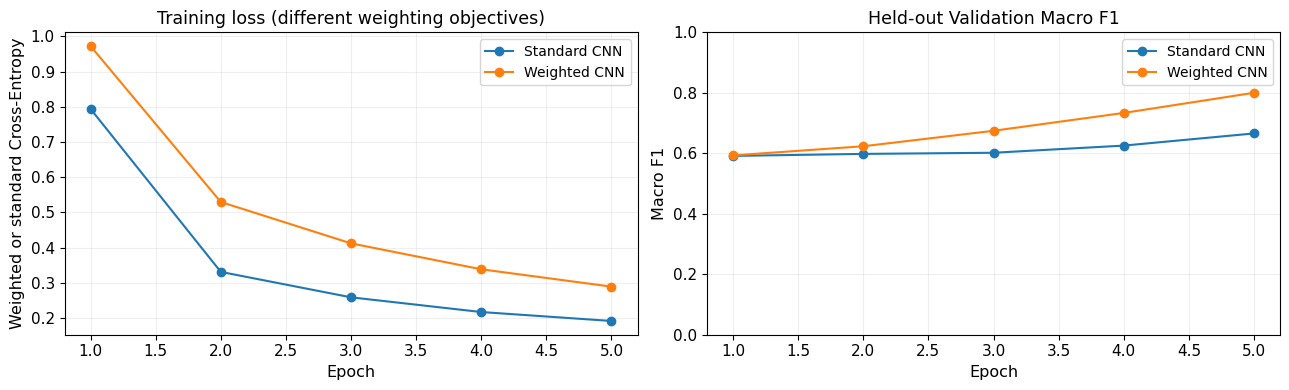

In [7]:
# ================= 06. Compare Validation Curves and Metrics =================

# ----------------------- 1. Compare Validation Metrics -----------------------
summary = pd.DataFrame([
    {"model": name,
     "macro_f1": f1_score(
         y_val, result["predicted"], labels=TASK_CLASSES,
         average="macro", zero_division=0),
     "balanced_accuracy": balanced_accuracy_score(y_val, result["predicted"]),
     "validation_windows": len(y_val)}
    for name, result in runs.items()
])

display(summary.round(4))

# ----------------- 2. Inspect Training and Validation Curves -----------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for name, result in runs.items():
    curve = result["history"]
    axes[0].plot(curve["epoch"], curve["train_loss"], marker="o", label=name)
    axes[1].plot(curve["epoch"], curve["validation_macro_f1"], marker="o", label=name)

axes[0].set(title="Training loss (different weighting objectives)",
            xlabel="Epoch", ylabel="Weighted or standard Cross-Entropy")
axes[1].set(title="Held-out Validation Macro F1", xlabel="Epoch",
            ylabel="Macro F1", ylim=(0, 1))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()


**07. Inspect Minority-Class Errors**

Compare class-level precision, recall, F1 and confusion matrices, with particular attention to Shuffling and stair activities.

,model,class,support,precision,recall,f1
0,Standard CNN,Walking,453,0.8845,0.9470,0.9147
1,Standard CNN,Running,78,0.9873,1.0000,0.9936
2,Standard CNN,Shuffling,15,0.0000,0.0000,0.0000
3,Standard CNN,Stairs ascending,30,1.0000,0.1000,0.1818
4,Standard CNN,Stairs descending,32,1.0000,0.1875,0.3158
5,Standard CNN,Standing,536,0.9331,0.9366,0.9348
6,Standard CNN,Sitting,1363,0.9749,0.9993,0.9870
7,Standard CNN,Lying,194,1.0000,0.9948,0.9974
8,Weighted CNN,Walking,453,0.9663,0.8874,0.9252
9,Weighted CNN,Running,78,1.0000,0.9744,0.9870


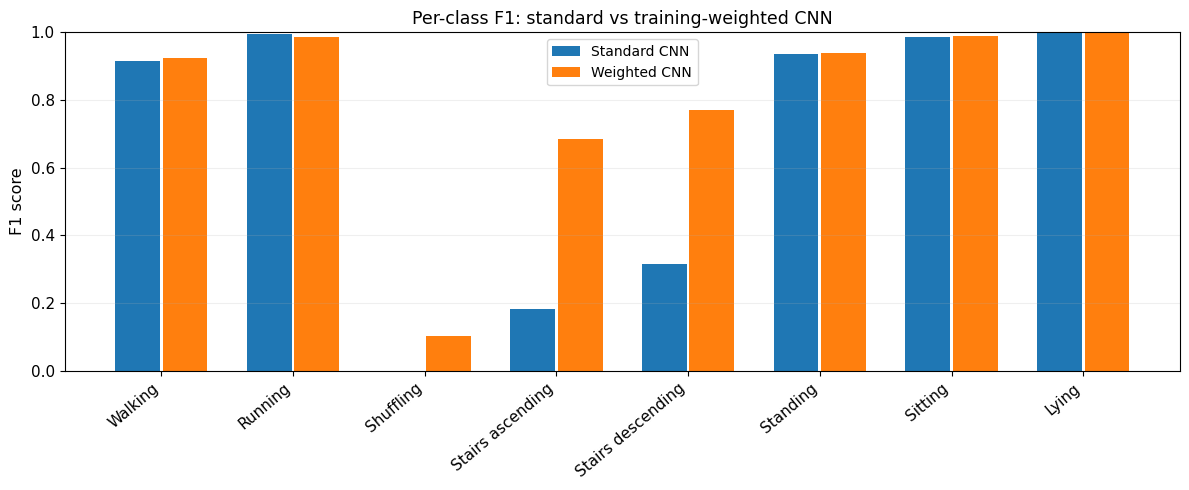

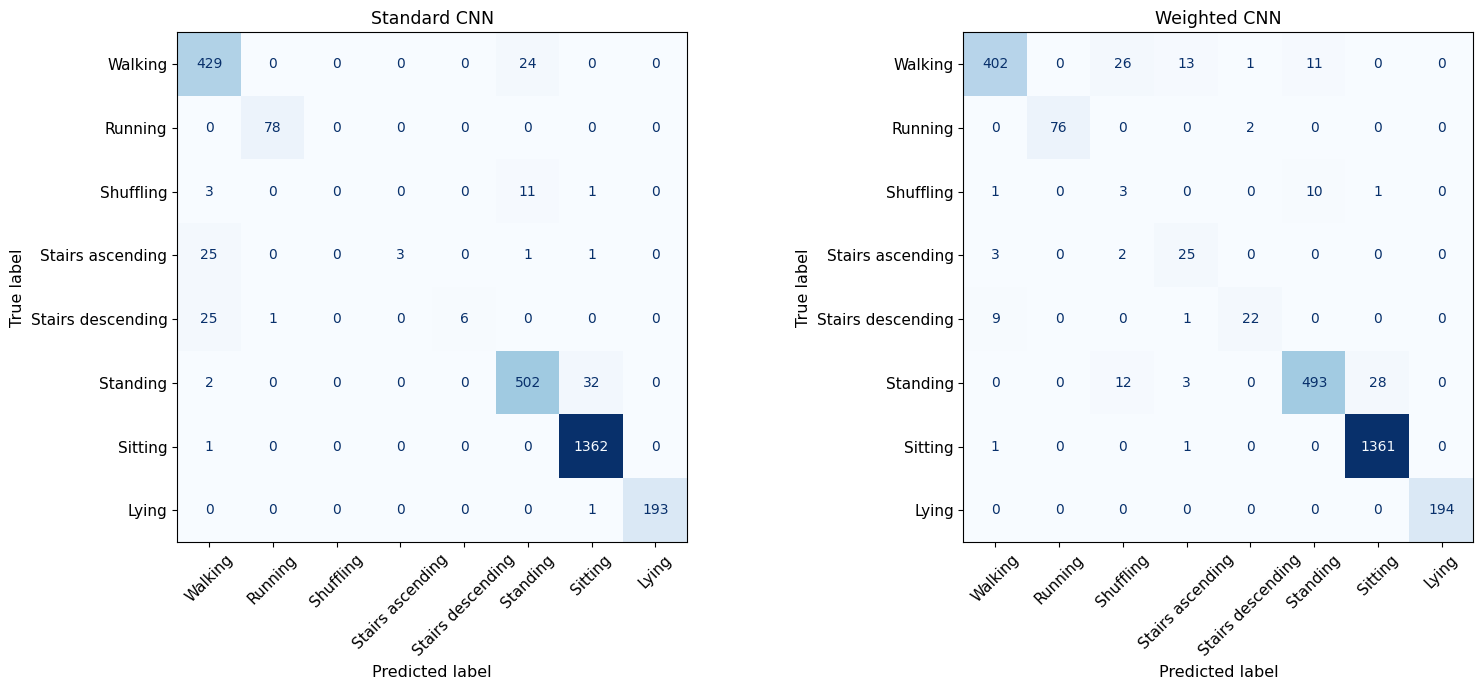

In [8]:
# =============== 07. Inspect Class-Level and Confusion Errors ================

# --------------------- 1. Calculate Class-Level Metrics ----------------------
reports = []

for name, result in runs.items():
    report = classification_class_report(
        y_val, result["predicted"], classes=TASK_CLASSES,
        class_names=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    )
    report["model"] = name
    reports.append(report)
class_table = pd.concat(reports, ignore_index=True)

display(class_table[["model", "class", "support", "precision", "recall", "f1"]].round(4))

# -------------------- 2. Compare Class F1 and Confusions ---------------------
fig, ax = plt.subplots(figsize=(12, 5))
positions = np.arange(len(TASK_CLASSES))

for i, name in enumerate(runs):
    values = class_table.loc[class_table["model"] == name, "f1"].to_numpy()
    ax.bar(positions + (i - 0.5) * 0.36, values, width=0.34, label=name)
ax.set_xticks(positions, [ACTIVITY_NAMES[c] for c in TASK_CLASSES], rotation=40, ha="right")
ax.set(title="Per-class F1: standard vs training-weighted CNN",
       ylabel="F1 score", ylim=(0, 1))
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (name, result) in zip(axes, runs.items()):
    matrix = confusion_matrix(y_val, result["predicted"], labels=TASK_CLASSES)
    ConfusionMatrixDisplay(
        confusion_matrix=matrix, display_labels=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    ).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
    ax.set_title(name)
fig.tight_layout()
plt.show()


**08. Compare Paired Participant-Level Changes**

Calculate fixed-task scores for each Validation participant under both loss conditions. Treat the results as descriptive rather than a statistical significance test.

,subject_id,score_a,score_b,difference_a_minus_b
0,S009,0.3297,0.2318,0.0978
1,S012,0.8951,0.5911,0.3040
2,S019,0.8374,0.5882,0.2492
3,S022,0.9012,0.6290,0.2722
4,S036,0.4898,0.5745,-0.0848
5,S037,0.7817,0.7463,0.0354


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN,Standard CNN,macro_f1_fixed_task,6,0.1457,0.1735,5,1,0


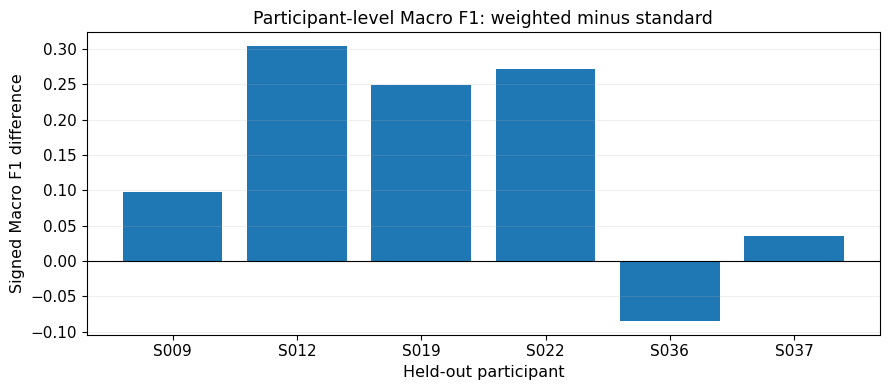

In [9]:
# ================= 08. Compare Matched Held-Out Participants =================

# ------------------- 1. Evaluate Paired Participant Scores -------------------
individual_results = pd.concat([
    evaluate_predictions_by_subject(
        y_val, result["predicted"], val_subject_ids,
        TASK_CLASSES, model_name=name,
    )
    for name, result in runs.items()
], ignore_index=True)
paired, paired_summary = compare_models_by_subject(
    individual_results, model_a="Weighted CNN", model_b="Standard CNN",
    score_column="macro_f1_fixed_task",
)

# ------------------- 2. Visualise Per-Participant Changes --------------------
display(paired.round(4))
display(pd.DataFrame([paired_summary]).round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(paired["subject_id"], paired["difference_a_minus_b"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Participant-level Macro F1: weighted minus standard",
       xlabel="Held-out participant", ylabel="Signed Macro F1 difference")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


**09. Scientific Quality Gate and Limitations**

Check shared source rows, group separation, Train-only weighting and complete evaluation outputs. One Development split and seed cannot establish a general class-weighting benefit or replace independent final Test evaluation.

In [ ]:
# ================= 09. Scientific Training-Loss Quality Gate =================

# ---------------- 1. Check Matched Source and Class Integrity ----------------
assert len(X_train) == len(y_train) and len(X_val) == len(y_val)
assert set(np.unique(y_train)) == set(TASK_CLASSES)

# ----------------- 2. Verify Test Exclusion and Predictions ------------------
assert not (set(val_subject_ids) & RESERVED_TEST)
assert all(len(item["predicted"]) == len(y_val) for item in runs.values())
assert len(paired) == len(set(val_subject_ids))
assert summary["macro_f1"].between(0, 1).all()

# ------------------------- 3. Quality Gate and Scope -------------------------
print("Training-loss ablation quality gate: PASSED")
print("Reserved original Test loaded/scored: NO")
print("Independent validation of weight benefits: NOT ESTABLISHED")


Training-loss ablation quality gate: PASSED
Reserved original Test loaded/scored: NO
Independent validation of weight benefits: NOT ESTABLISHED
